# Content

Use authorize librairies to train classifier

# Imports

In [1]:
import numpy as np 
import matplotlib.pyplot as plt 
import pandas as pd
from sklearn.metrics import confusion_matrix
import seaborn as sns
import statsmodels.formula.api as smf
import sklearn

# Load data

In [2]:
#Save in .npy format
x_train_clean = np.load("x_train_clean.npy")
x_test_clean = np.load("x_test_clean.npy")
y_train = np.load("y_train.npy")

#Eliminate first columns (here 10 first columns)
d = 10
x_train_clean_useful = x_train_clean[:, d:]
x_test_clean_useful = x_test_clean[:, d:]

#Eliminate index column
y_train_useful = y_train[:, 1].reshape(-1, 1)
y_train_useful = (y_train_useful + 1)/2

# Useful functions

In [3]:
def sigmoid(t):
    """apply sigmoid function on t.

    Args:
        t: scalar or numpy array

    Returns:
        scalar or numpy array
    """
    return(1/(1+np.exp(-t)))



def calculate_loss(y, tx, w):
    """compute the cost by negative log likelihood.

    Args:
        y:  shape=(N, 1)
        tx: shape=(N, D)
        w:  shape=(D, 1)

    Returns:
        a non-negative loss
    """
    assert y.shape[0] == tx.shape[0]
    assert tx.shape[1] == w.shape[0]

    N = len(y)
    loss = 1/N * np.sum(-y * (tx @ w) + np.logaddexp(0, tx @ w))
    return(loss)



def calculate_gradient(y, tx, w):
    """compute the gradient of loss.

    Args:
        y:  shape=(N, 1)
        tx: shape=(N, D)
        w:  shape=(D, 1)

    Returns:
        a vector of shape (D, 1)
    """
    N = len(y)
    gradient = 1/N * tx.T @ (sigmoid(tx @ w) - y)
    return(gradient)



def learning_by_gradient_descent(y, tx, w, gamma):
    """
    Do one step of gradient descent using logistic regression. Return the loss and the updated w.

    Args:
        y:  shape=(N, 1)
        tx: shape=(N, D)
        w:  shape=(D, 1)
        gamma: float

    Returns:
        loss: scalar number
        w: shape=(D, 1)
    """
    #Gradient
    gradient = calculate_gradient(y, tx, w)
    w_new = w - gamma * gradient
    loss = calculate_loss(y, tx, w)
    return(loss, w_new)

In [4]:
def logistic_regression(y, tx, w):
    """return the loss, gradient of the loss, and hessian of the loss.

    Args:
        y:  shape=(N, 1)
        tx: shape=(N, D)
        w:  shape=(D, 1)

    Returns:
        loss: scalar number
        gradient: shape=(D, 1)
        hessian: shape=(D, D)
    """
    gradient = calculate_gradient(y, tx, w)
    loss = calculate_loss(y, tx, w)
    return(loss, gradient)


def penalized_logistic_regression(y, tx, w, lambda_):
    """return the loss and gradient.

    Args:
        y:  shape=(N, 1)
        tx: shape=(N, D)
        w:  shape=(D, 1)
        lambda_: scalar

    Returns:
        loss: scalar number
        gradient: shape=(D, 1)
    """
    loss, gradient = logistic_regression(y, tx, w)

    #Penalization into account
    loss_penalized = loss + 1/2 * lambda_ * w.T @ w
    gradient_penalized = gradient + lambda_ * np.eye(len(w)) @ w
    return(loss_penalized, gradient_penalized)


def learning_by_penalized_gradient(y, tx, w, gamma, lambda_):
    """
    Do one step of gradient descent, using the penalized logistic regression.
    Return the loss and updated w.

    Args:
        y:  shape=(N, 1)
        tx: shape=(N, D)
        w:  shape=(D, 1)
        gamma: scalar
        lambda_: scalar

    Returns:
        loss: scalar number
        w: shape=(D, 1)
    """
    #Penalized loss and gradient
    loss, gradient = penalized_logistic_regression(y, tx, w, lambda_)

    #Update
    w_new = w - gamma * gradient
    return loss, w_new

# Data factoring

In [5]:
#Dtype (to change in case of being unable to allocate matrices with large type. Can be changed to np.float32)
dtype_array = np.float32

#Train/valdiation split
#Mask definition
rng = np.random.default_rng()
n = len(y_train_useful)
ratio_mask = 33
mask = rng.random(n) >= ratio_mask / 100

#Train/validation split
x_tr = x_train_clean_useful[mask]
y_tr = y_train_useful[mask]
x_te = x_train_clean_useful[~mask]
y_te = y_train_useful[~mask]

#Normalization
x_tr_norm = (x_tr - np.mean(x_tr)) / (np.std(x_tr))
y_tr_norm = (y_tr - np.mean(y_tr)) / (np.std(y_tr))
x_te_norm = (x_te - np.mean(x_te)) / (np.std(x_te))
y_te_norm = (y_te - np.mean(y_te)) / (np.std(y_te))

#Tx
tx_tr_norm = np.c_[np.ones((y_tr_norm.shape[0], 1)), x_tr_norm]
tx_tr_norm = tx_tr_norm.astype(dtype_array)
tx_te_norm = np.c_[np.ones((y_te_norm.shape[0], 1)), x_te_norm]
tx_te_norm = tx_te_norm.astype(dtype_array)

# 1-Logistic regression

#### a-Training functions

In [6]:
#General purpose function

def logistic_regression_optim(w0, gamma, max_iter, y_tr_norm, tx_tr_norm, y_te_norm, tx_te_norm) :
    w = w0
    losses_train = []
    losses_test = []

    #Optimization loop
    for iter in range(max_iter):
        # get loss and update w.
        loss_train, w = learning_by_gradient_descent(y_tr_norm, tx_tr_norm, w, gamma)
        loss_test = calculate_loss(y_te_norm, tx_te_norm, w)
        # log info
        if iter % 100 == 0:
            print("Current iteration={i}, loss_train={l_tr}, loss_test={l_te}".format(i=iter, l_tr=loss_train, l_te=loss_test))
        # converge criterion
        losses_train.append(loss_train)
        losses_test.append(loss_test)

    return(w, losses_train, losses_test)

def penalized_logistic_regression_optim(w0, gamma, lambda_, max_iter, y_tr_norm, tx_tr_norm, y_te_norm, tx_te_norm) :
    w = w0
    losses_train = []
    losses_test = []

    #Optimization loop
    for iter in range(max_iter):
        # get loss and update w.
        loss_train, w = learning_by_penalized_gradient(y_tr_norm, tx_tr_norm, w, gamma, lambda_)
        loss_test = calculate_loss(y_te_norm, tx_te_norm, w)
        # log info
        if iter % 100 == 0:
            print("Current iteration={i}, loss_train={l_tr}, loss_test={l_te}".format(i=iter, l_tr=loss_train[0][0], l_te=loss_test))
        # converge criterion
        losses_train.append(loss_train[0][0])
        losses_test.append(loss_test)

    return(w, losses_train, losses_test)

#### b-Training

In [7]:
#logistic regression
w0 = np.zeros((tx_tr_norm.shape[1], 1), dtype=dtype_array)
gamma = 0.01
lambda_ = 0.75
max_iter = 300

#Pure logistic regression
w_log, losses_train_log, losses_test_log = logistic_regression_optim(w0, gamma, max_iter, y_tr, tx_tr_norm, y_te, tx_te_norm)
print("\n")

#Penalized logistic regression
w_log_pen, losses_train_log_pen, losses_test_log_pen = penalized_logistic_regression_optim(w0, gamma, lambda_, max_iter, y_tr, tx_tr_norm, y_te, tx_te_norm)

Current iteration=0, loss_train=0.6931471824645996, loss_test=0.6050467381528865
Current iteration=100, loss_train=0.3568416892588462, loss_test=0.35803597904192164
Current iteration=200, loss_train=0.35094005547808643, loss_test=0.3521720481804615


Current iteration=0, loss_train=0.6931471824645996, loss_test=0.6050467381528865
Current iteration=100, loss_train=0.3850189550546191, loss_test=0.3630614422573199
Current iteration=200, loss_train=0.3842753220187321, loss_test=0.36090900969547973


#### c-Results

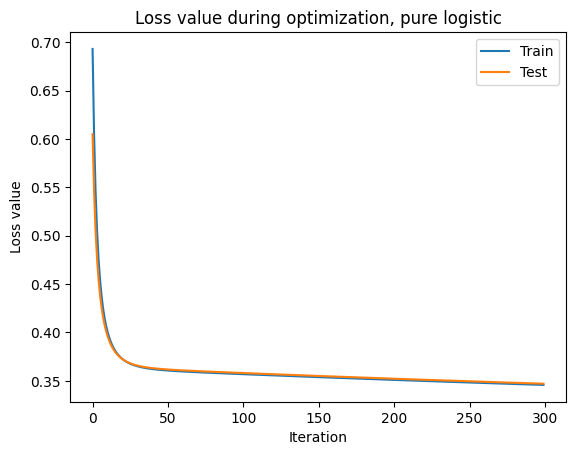

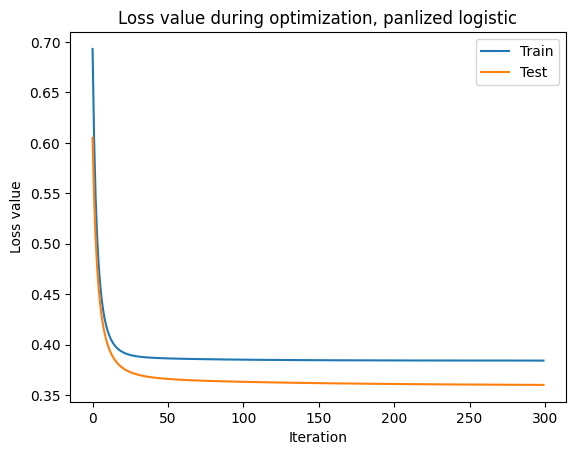

In [8]:
#Loss display: pure logistic
plt.plot(losses_train_log, label="Train")
plt.plot(losses_test_log, label="Test")
plt.ylabel("Loss value")
plt.xlabel("Iteration")
plt.title("Loss value during optimization, pure logistic")
plt.legend(loc="upper right")
plt.show()

#Loss display: penalized logistic
plt.plot(losses_train_log_pen, label="Train")
plt.plot(losses_test_log_pen, label="Test")
plt.ylabel("Loss value")
plt.xlabel("Iteration")
plt.title("Loss value during optimization, panlized logistic")
plt.legend(loc="upper right")
plt.show()

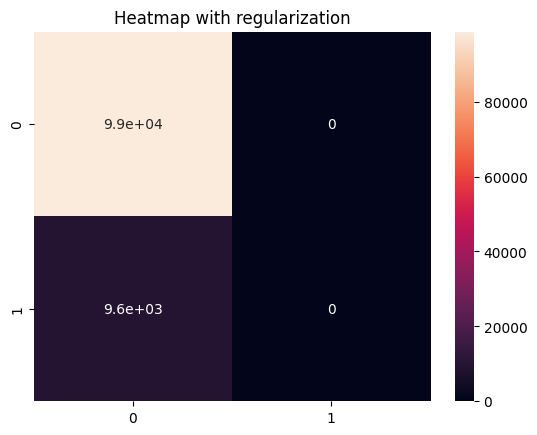

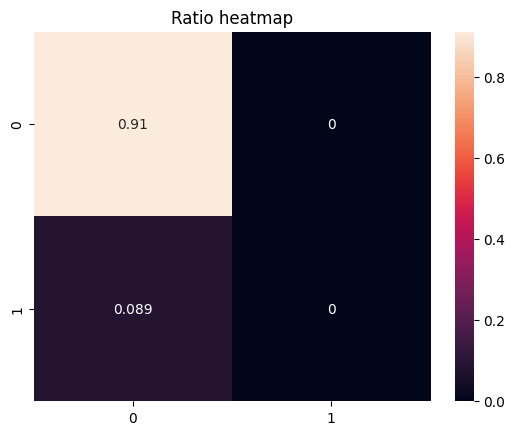

In [9]:
#Pure logistic
#Class choice
logistic_mask_log = sigmoid(tx_te_norm @ w_log) >= 0.5
y_te_pred_log = np.zeros((np.shape(tx_te_norm)[0],1))
y_te_pred_log[logistic_mask_log] = 1

#Confusion matrix
cm_log = confusion_matrix(y_te, y_te_pred_log)

#Heatmap
sns.heatmap(cm_log, annot=True)
plt.title("Heatmap with regularization")
plt.show()

#Percentage confusion matrix
cm_ratio_log = cm_log/len(y_te)

#Heatmap
sns.heatmap(cm_ratio_log, annot=True)
plt.title("Ratio heatmap")
plt.show()

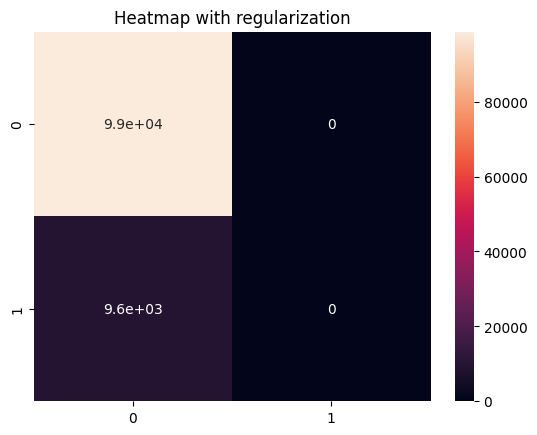

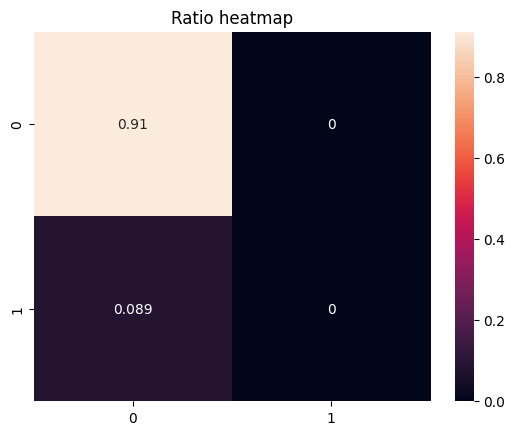

In [10]:
#penalizeg logistic
#Class choice
logistic_mask_log_pen = sigmoid(tx_te_norm @ w_log_pen) >= 0.5
y_te_pred_log_pen = np.zeros((np.shape(tx_te_norm)[0],1))
y_te_pred_log_pen[logistic_mask_log_pen] = 1

#Confusion matrix
cm_log_pen = confusion_matrix(y_te, y_te_pred_log_pen)

#Heatmap
sns.heatmap(cm_log_pen, annot=True)
plt.title("Heatmap with regularization")
plt.show()

#Percentage confusion matrix
cm_ratio_log_pen = cm_log_pen/len(y_te)

#Heatmap
sns.heatmap(cm_ratio_log_pen, annot=True)
plt.title("Ratio heatmap")
plt.show()

# 2-kNN (from sklearn)

#### a-Training

In [11]:
#Fit
neigh = sklearn.neighbors.KNeighborsClassifier(n_neighbors=2)
neigh.fit(x_tr, y_tr.ravel())

#Predict
y_te_pred_kNN = neigh.predict(x_te)

#### b-Results

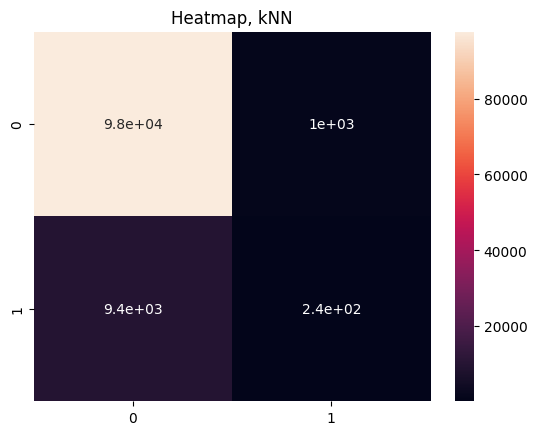

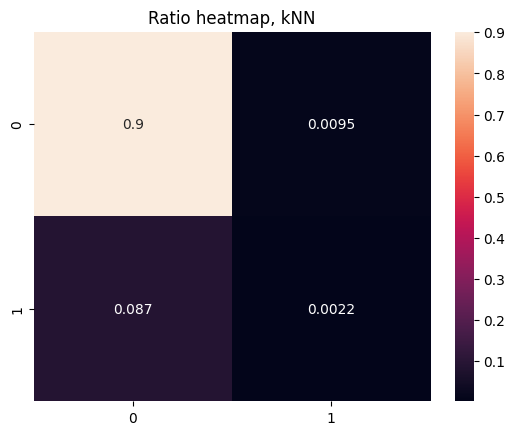

In [12]:
#Confusion matrix
cm_kNN = confusion_matrix(y_te, y_te_pred_kNN)

#Heatmap
sns.heatmap(cm_kNN, annot=True)
plt.title("Heatmap, kNN")
plt.show()

#Percentage confusion matrix
cm_ratio_kNN = cm_kNN/len(y_te)

#Heatmap
sns.heatmap(cm_ratio_kNN, annot=True)
plt.title("Ratio heatmap, kNN")
plt.show()

# 3-Custom kNN

In [13]:
def kNN_custom(x_tr, y_tr, x_te, N) :
    n = len(x_te)
    y_te_pred = np.zeros((n, 1))
    for i in range(n) :
        print(i)
        x_te_case = x_te[i, :]

        #Distances
        distances = np.linalg.norm(x_tr - x_te_case, axis=1)
        
        #N indices of min distance
        indices = np.argpartition(distances, N - 1)[:N]

        #Counting of classes corresponding to above indices
        values, counts = np.unique(y_tr[indices], return_counts=True)

        #Class prediction
        class_pred = values[np.argmax(counts)]  
        y_te_pred[i,0] = class_pred
    
    return(y_te_pred)

def kNN_custom_vectorized(x_tr, y_tr, x_te, N, batch_size=100):
    x_tr = np.asarray(x_tr)
    x_te = np.asarray(x_te)
    y_tr = np.asarray(y_tr).ravel()

    n_test = len(x_te)
    y_te_pred = np.empty((n_test, 1), dtype=y_tr.dtype)

    # Process test samples in batches
    for start in range(0, n_test, batch_size):
        end = min(start + batch_size, n_test)
        x_batch = x_te[start:end]

        # Compute squared Euclidean distances without a 3D array
        distances = (
            np.sum(x_batch**2, axis=1)[:, None]
            + np.sum(x_tr**2, axis=1)[None, :]
            - 2 * x_batch @ x_tr.T
        )

        # Select N nearest neighbors
        indices = np.argpartition(
            distances, N - 1, axis=1
        )[:, :N]

        # Majority vote
        for i, idx in enumerate(indices):
            values, counts = np.unique(y_tr[idx], return_counts=True)
            y_te_pred[start + i, 0] = values[np.argmax(counts)]

    return y_te_pred

In [14]:
#kNN_custom_vectorized(x_tr, y_tr, x_te, 2)

# 4-Linker with Fiona

#### a-Helpers functions

In [15]:
"""some helper functions for data pre-processing."""

import numpy as np
import os

# Derived variables to exclude
DESIGN = {"_STATE", 
          "_PSU", 
          "_STSTR", 
          "_STRWT", 
          "_RAWRAKE", 
          "_WT2RAKE",
          "_CHISPNC", 
          "_CRACE1", 
          "_CPRACE", 
          "_CLLCPWT", 
          "_DUALUSE",
          "_DUALCOR", 
          "_LLCPWT"}

# Derived variables to exclude
FLAGS  = {"_MISFRTN", 
          "_MISVEGN", 
          "_FRTRESP", 
          "_VEGRESP",
          "_FRT16", 
          "_VEG23", 
          "_FRUITEX", 
          "_VEGETEX"}

# Information on how missing values are encoded
MISSING_CODES = { "_RFHLTH": {9},
                    "_HCVU651": set(), 
                    "_RFHYPE5": {9},
                    "_CHOLCHK": {9},
                    "_RFCHOL": {9},
                    "_LTASTH1": {9},
                    "_CASTHM1": {9},
                    "_ASTHMS1": {9},
                    "_DRDXAR1": set(), 
                    "_PRACE1": {77, 99},
                    "_MRACE1": {77, 99},
                    "_HISPANC": {9},
                    "_RACE": {9},
                    "_RACEG21": {9},
                    "_RACEGR3": {9},
                    "_RACE_G1": set(),  
                    "_AGEG5YR": {14},
                    "_AGE65YR": {3},
                    "_AGE80": set(),  
                    "_AGE_G": set(),  
                    "_BMI5": set(), 
                    "_BMI5CAT": set(), 
                    "_RFBMI5": {9},
                    "_CHLDCNT": {9},
                    "_EDUCAG": {9},
                    "_INCOMG": {9},
                    "_SMOKER3": {9},
                    "_RFSMOK3": {9},
                    "_RFBING5": {9},
                    "_DRNKWEK": {99900},
                    "_RFDRHV5": {9},
                    "_FRUTSUM": set(),  
                    "_VEGESUM": set(),  
                    "_FRTLT1": {9},
                    "_VEGLT1": {9},
                    "_TOTINDA": {9},
                    "_MINAC11": set(),  
                    "_MINAC21": set(),  
                    "_PACAT1": {9},
                    "_PAINDX1": {9},
                    "_PA150R2": {9},
                    "_PA300R2": {9},
                    "_PA30021": {9},
                    "_PASTRNG": {9},
                    "_PAREC1": {9},
                    "_PASTAE1": {9},
                    "_LMTACT1": {9},
                    "_LMTWRK1": {9},
                    "_LMTSCL1": {9},
                    "_RFSEAT2": {9},
                    "_RFSEAT3": {9},
                    "_FLSHOT6": {9},
                    "_PNEUMO2": {9},
                    "_AIDTST3": {9}}

# Continuous variables
CONT_VARS = {"_BMI5",    
                "_HTIN4",   
                "_HTM4",     
                "_WTKG3",    
                "_DRNKWEK",  
                "_FRUTSUM",
                "_VEGESUM"}

# Decimal variables
DEC_VARS = {"_BMI5",
            "_DRNKWEK", 
            "_FRUTSUM", 
            "_VEGESUM"}



def replace_missing_codes(data_x, selected_headers):
    """Replace values indicating missing data with NaN."""

    data_x = np.asarray(data_x, dtype=float).copy()

    for j, name in enumerate(selected_headers):
        codes = MISSING_CODES.get(name, set())

        if codes:
            mask = np.isin(data_x[:, j], list(codes))
            data_x[mask, j] = np.nan

    return data_x


def replace_nan_by_mode(col):
    """Replace NaN values with the column's mode."""

    mask_nan = np.isnan(col)
    valid_vals = col[~mask_nan]
        
    if len(valid_vals) > 0:
        vals, counts = np.unique(valid_vals, return_counts=True)
        mode_val = vals[np.argmax(counts)]
        col[mask_nan] = mode_val
    else:
        col[mask_nan] = 0  

    return col, mode_val
    


def replace_nan_by_mean(col):
    """Replace NaN values with the column's mean safely."""

    mask_nan = np.isnan(col)
    valid_vals = col[~mask_nan]
    
    if len(valid_vals) > 0:
        mean_val = np.mean(valid_vals)
        col[mask_nan] = mean_val
    else:
        mean_val = 0.0
        col[mask_nan] = mean_val
    
    return col, mean_val


def one_hot_encode(col):
    """One-hot encode categorical variables."""
        
    unique_vals = np.unique(col)

    # Discard one value for linear independence
    unique_vals = unique_vals[1:] 
        
    n_samples = len(col)
    encoded_col = np.zeros((n_samples, len(unique_vals)), dtype=int)
    
    for idx, val in enumerate(unique_vals):
        encoded_col[col == val, idx] = 1

    return encoded_col, unique_vals


def standardize(col):
    """Standardize continuous variables."""

    mean_col = np.mean(col)
    mean_sub_col = col - mean_col
    std_col = np.std(col)

    if std_col == 0:
        std_col = 1.0

    standardized_col = mean_sub_col / std_col

    return standardized_col, mean_col, std_col


def load_data_train(data_dir, imputation=True):
    """Load data for training."""

    path_dataset_x = os.path.join(data_dir, "x_train.csv")
    path_dataset_y = os.path.join(data_dir, "y_train.csv")

    header = np.genfromtxt(path_dataset_x, delimiter=",", names=True, max_rows=1).dtype.names

    # Extract only derived variables
    derived_var = [i for i, s in enumerate(header) if s.startswith("_") and s not in DESIGN | FLAGS]

    derived_var_header = [header[i] for i in derived_var]
   
    data_x = np.genfromtxt(path_dataset_x, delimiter=",", skip_header=1, usecols=derived_var)
    data_y = np.genfromtxt(path_dataset_y, delimiter=",", skip_header=1, usecols=1)

    # Mark all missing values as NaN
    data_x = replace_missing_codes(data_x, derived_var_header)

    # Process each column according to specifications
    processed_cols = []
    cont_params = {}
    cat_params = {}

    if imputation:

        mask_nan = np.zeros(data_x.shape[1])
        for idx, col_name in enumerate(derived_var_header):
                
            col = data_x[:, idx]
    
            # Adjust decimal variables
            if col_name in DEC_VARS:
                col = col / 100
    
            # Replace NaN with mean for continuous variables and standardize
            if col_name in CONT_VARS:
                col_no_nan, mean_val = replace_nan_by_mean(col)
                standardized_col, mean_col, std_col = standardize(col_no_nan)
                processed_cols.append(standardized_col.reshape(-1, 1))
                cont_params[col_name] = {'mean_val': mean_val, 'mean_col': mean_col, 'std_col': std_col}
    
            # Replace NaN with mode for categorical variables and one-hot-encode
            else:
                col_no_nan, mode_val = replace_nan_by_mode(col)
                encoded_col, unique_vals = one_hot_encode(col_no_nan)
                processed_cols.append(encoded_col)
                cat_params[col_name] = {'mode_val': mode_val, 'unique_vals': unique_vals}

    else:
        mask_nan = np.isnan(data_x).any(axis=0)
        data_x = data_x[:, ~mask_nan]

        # Keep only the headers where the mask is True 
        derived_var_header_filtered = [name for name, keep in zip(derived_var_header, ~mask_nan) if keep]

        print(f"Reduced to {data_x.shape[1]} features.")
        print(derived_var_header_filtered)

        for idx, col_name in enumerate(derived_var_header_filtered):
                        
            col = data_x[:, idx]
    
            # Adjust decimal variables
            if col_name in DEC_VARS:
                col = col / 100
    
            # Replace NaN with mean for continuous variables and standardize
            if col_name in CONT_VARS:
                standardized_col, mean_col, std_col = standardize(col)
                processed_cols.append(standardized_col.reshape(-1, 1))
                cont_params[col_name] = {'mean_col': mean_col, 'std_col': std_col}
    
            # Replace NaN with mode for categorical variables and one-hot-encode
            else:
                col_no_nan, mode_val = replace_nan_by_mode(col)
                encoded_col, unique_vals = one_hot_encode(col)
                processed_cols.append(encoded_col)
                cat_params[col_name] = {'mode_val': mode_val, 'unique_vals': unique_vals}
    
    # Transform labels from -1, 1 to 0, 1
    data_y = (data_y == 1).astype(float)

    return np.hstack(processed_cols), np.array(data_y), cont_params, cat_params, mask_nan


def load_data_test(data_dir, cont_params, cat_params, mask_nan, imputation=True):
    """Load data for testing."""
    path_dataset_x = os.path.join(data_dir, "x_test.csv")
    
    header = np.genfromtxt(path_dataset_x, delimiter=",", names=True, max_rows=1).dtype.names
    
    # Extract only derived variables
    derived_var = [i for i, s in enumerate(header) if s.startswith("_") and s not in DESIGN | FLAGS]

    derived_var_header = [header[i] for i in derived_var]
    
    data_x = np.genfromtxt(path_dataset_x, delimiter=",", skip_header=1, usecols=derived_var)

    # Mark all missing values as NaN
    data_x = replace_missing_codes(data_x, derived_var_header)

    # Process each column according to specifications
    processed_cols = []

    if imputation:

        for idx, col_name in enumerate(derived_var_header):
                    
            col = data_x[:, idx]
    
            # Adjust decimal variables
            if col_name in DEC_VARS:
                col = col / 100
    
            # Replace NaN with mean for continuous variables and standardize
            if col_name in CONT_VARS:
                params = cont_params[col_name]
                mask_nan = np.isnan(col)
                col[mask_nan] = params['mean_val']
                mean_sub_col = col - params['mean_col']
                standardized_col = mean_sub_col / params['std_col']
                processed_cols.append(standardized_col.reshape(-1, 1))
    
            # Replace NaN with mode for categorical variables and one-hot-encode
            else:
                params = cat_params[col_name]
                mask_nan = np.isnan(col)
                col[mask_nan] = params['mode_val']
                
                n_samples = len(col)
                encoded_col = np.zeros((n_samples, len(params['unique_vals'])), dtype=int)
                
                for u_idx, val in enumerate(params['unique_vals']):
                    encoded_col[col == val, u_idx] = 1
    
                processed_cols.append(encoded_col)
        
    else:

        data_x = data_x[:, ~mask_nan]

        derived_var_header_filtered = [name for name, keep in zip(derived_var_header, ~mask_nan) if keep]
    
        for idx, col_name in enumerate(derived_var_header_filtered):
                    
            col = data_x[:, idx]
    
            # Adjust decimal variables
            if col_name in DEC_VARS:
                col = col / 100
    
            # Replace NaN with mean for continuous variables and standardize
            if col_name in CONT_VARS:
                params = cont_params[col_name]
                mask_nan = np.isnan(col)
                col[mask_nan] = params['mean_val']
                mean_sub_col = col - params['mean_col']
                standardized_col = mean_sub_col / params['std_col']
                processed_cols.append(standardized_col.reshape(-1, 1))
    
            # Replace NaN with mode for categorical variables and one-hot-encode
            else:
                params = cat_params[col_name]
                mask_nan = np.isnan(col)
                col[mask_nan] = params['mode_val']
                
                n_samples = len(col)
                encoded_col = np.zeros((n_samples, len(params['unique_vals'])), dtype=int)
                
                for u_idx, val in enumerate(params['unique_vals']):
                    encoded_col[col == val, u_idx] = 1
    
                processed_cols.append(encoded_col)

    return np.hstack(processed_cols)


def downsample_classes(data_x, data_y, random_state=0):
    """Downsamples the majority class to match the size of the minority class."""
    
    np.random.seed(random_state)
    
    # Identify indices for each class
    minority_class_val = 1.0 if np.sum(data_y == 1.0) < np.sum(data_y == 0.0) else 0.0
    majority_class_val = 0.0 if minority_class_val == 1.0 else 1.0
    
    minority_indices = np.where(data_y == minority_class_val)[0]
    majority_indices = np.where(data_y == majority_class_val)[0]
    
    n_minority = len(minority_indices)
    
    downsampled_majority_indices = np.random.choice(majority_indices, size=n_minority, replace=False)
    
    balanced_indices = np.concatenate([minority_indices, downsampled_majority_indices])
    np.random.shuffle(balanced_indices)
    
    return data_x[balanced_indices], data_y[balanced_indices]
    

In [28]:
def mean_squared_error_gd(y, x, initial_w, max_iters, gamma):
    """Implementation of the Gradient Descent algorithm using mean squared loss function.
    
        Args:
            y: numpy array of shape=(N, )
            x: numpy array of shape=(N,D)
            initial_w: numpy array of shape=(D, )
            max_iters: scalar denoting the total number of iterations
            gamma: scalar denoting the stepsize
    
        Returns:
            w: numpy array of shape=(D, ) denoting the final model parameters
            loss: scalar denoting final loss value
        """
    w = initial_w
    N = len(y)
    for n_iter in range(max_iters):
        e = y - x@w
        grad = 1/N * (x.T@e)
        w = w + gamma * grad

    e = y - x@w
    loss = 1/2 * 1/N * np.sum(e**2)
    
    return w, loss


def mean_squared_error_sgd(y, x, initial_w, max_iters, gamma):
    """Implementation of the Stochastic Gradient Descent algorithm with batch_size=1 using mean squared loss function.
    
        Args:
            y: numpy array of shape=(N, )
            x: numpy array of shape=(N,D)
            initial_w: numpy array of shape=(D, )
            max_iters: scalar denoting the total number of iterations
            gamma: scalar denoting the stepsize
    
        Returns:
            w: numpy array of shape=(D, ) denoting the final model parameters
            loss: scalar denoting final loss value
        """
    w = initial_w
    N = len(y)
    for n_iter in range(max_iters):
        idx = np.random.randint(N)
        e = y[idx] - x[idx]@w
        grad = x[idx]*e
        w = w + gamma * grad

    e = y - x@w
    loss = 1/2 * 1/N * np.sum(e**2)
    
    return w, loss


def least_squares(y, tx):
    """Implementation of the least squares solution using normal equations.

    Args:
        y: numpy array of shape (N,), N is the number of samples
        tx: numpy array of shape (N,D), D is the number of features

    Returns:
        w: numpy array of shape=(D, ) denoting the model parameters
        mse: scalar denoting mean square error
    """
    w = np.linalg.solve(tx.T@tx, tx.T@y)
    e = y - tx@w
    mse = np.sum(e**2) / (2 * len(y))

    return w, mse


def ridge_regression(y, tx, lambda_):
    """Implementation of ridge regression.

    Args:
        y: numpy array of shape (N,), N is the number of samples.
        tx: numpy array of shape (N,D), D is the number of features.
        lambda_: scalar.

    Returns:
        w: numpy array of shape=(D, ) denoting the model parameters
        mse: scalar denoting mean square error mean square error
    """
    aI = 2 * tx.shape[0] * lambda_ * np.identity(tx.shape[1])
    a = tx.T.dot(tx) + aI
    b = tx.T.dot(y)
    w = np.linalg.solve(a, b)
    e = y - tx@w
    mse = np.sum(e**2) / (2 * len(y))

    return w, mse


def logistic_regression(y, tx, initial_w, max_iters, gamma):
    """Implementation of logistic regression.

    Args:
        y:  shape=(N, 1)
        tx: shape=(N, D)
        initial_w:  shape=(D, 1)
        max_iters: scalar denoting the total number of iterations
        gamma: scalar denoting the stepsize


    Returns:
        w: numpy array of shape=(D, ) denoting the final model parameters
        loss: scalar denoting final loss value
    """

    w = initial_w
    N = len(y)
    for n_iter in range(max_iters):
        grad = tx.T@(1/(1+np.exp(-tx@w)) - y)/N
        w = w - gamma * grad

    loss = np.mean(-y*(tx@w) + np.log(1 + np.exp(tx@w)))
    
    return w, loss

def reg_logistic_regression(y, tx, lambda_, initial_w, max_iters, gamma):
    """Implementation of logistic regression.

    Args:
        y:  shape=(N, 1)
        tx: shape=(N, D)
        initial_w:  shape=(D, 1)
        max_iters: scalar denoting the total number of iterations
        gamma: scalar denoting the stepsize


    Returns:
        w: numpy array of shape=(D, ) denoting the final model parameters
        loss: scalar denoting final loss value
    """

    w = initial_w
    N = len(y)
    for n_iter in range(max_iters):
        grad = tx.T@(1/(1+np.exp(-tx@w)) - y)/N + 2 * lambda_ * w 
        w = w - gamma * grad

    loss = np.mean(-y*(tx@w) + np.log(1 + np.exp(tx@w)))
    
    return w, loss

In [93]:
def plot_heatmap(y_te, y_pred, title) : 
    #Confusion matrix
    cm = confusion_matrix(y_te, y_pred)

    #Percentage confusion matrix
    cm_ratio = cm/len(y_te)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    sns.heatmap(cm, ax=axes[0], annot=True, cmap="coolwarm")
    axes[0].set_title(f"Heatmap {title}")

    sns.heatmap(cm_ratio, ax=axes[1], annot=True, cmap="coolwarm")
    axes[1].set_title(f"Ratio heatmap {title}")

    fig.tight_layout()
    fig.savefig(f"heatmap_{title}.png", dpi=300)
    plt.show()

#### b-Data preprocessing

In [25]:
import numpy as np
import os

DATA_DIR = ""

# Load and clean data
x_train, y_train, cont_params, cat_params, mask = load_data_train(DATA_DIR, imputation=False)
x_test = load_data_test(DATA_DIR, cont_params, cat_params, mask, imputation=False)

Reduced to 3 features.
['_HCVU651', '_AGE80', '_AGE_G']


In [51]:
#Dtype (to change in case of being unable to allocate matrices with large type. Can be changed to np.float32)
dtype_array = np.float32

#Train/validation split
#Mask definition
rng = np.random.default_rng()
n = len(y_train_useful)
ratio_mask = 33
mask = rng.random(n) >= ratio_mask / 100

#Train/validation split
x_tr = x_train[mask]
y_tr = y_train[mask]
x_te = x_train[~mask]
y_te = y_train[~mask]

#Add intercept
tx_tr = np.c_[np.ones((x_tr.shape[0], 1)), x_tr]
tx_tr = tx_tr.astype(dtype_array)
tx_te = np.c_[np.ones((x_te.shape[0], 1)), x_te]
tx_te = tx_te.astype(dtype_array)

# Initialize weights
initial_w = np.zeros(tx_tr.shape[1])

# Sanity check of dimensions
print(tx_tr.shape)
print(y_tr.shape)
print(initial_w.shape)

(220144, 70)
(220144,)
(70,)


#### c-Logistic regression

In [54]:
#Optimization params
max_iters = 500
gamma = 0.01
lambda_ = 0.5

#Pure logistic regression
w_fiona, loss_fiona = logistic_regression(y_tr, tx_tr, initial_w, max_iters, gamma)
print("Pure logistic regression: OK")

#Penalized logistic regression
w_fiona_reg, loss_fiona_reg = reg_logistic_regression(y_tr, tx_tr, lambda_, initial_w, max_iters, gamma)
print("Penalized logistic regression: OK")

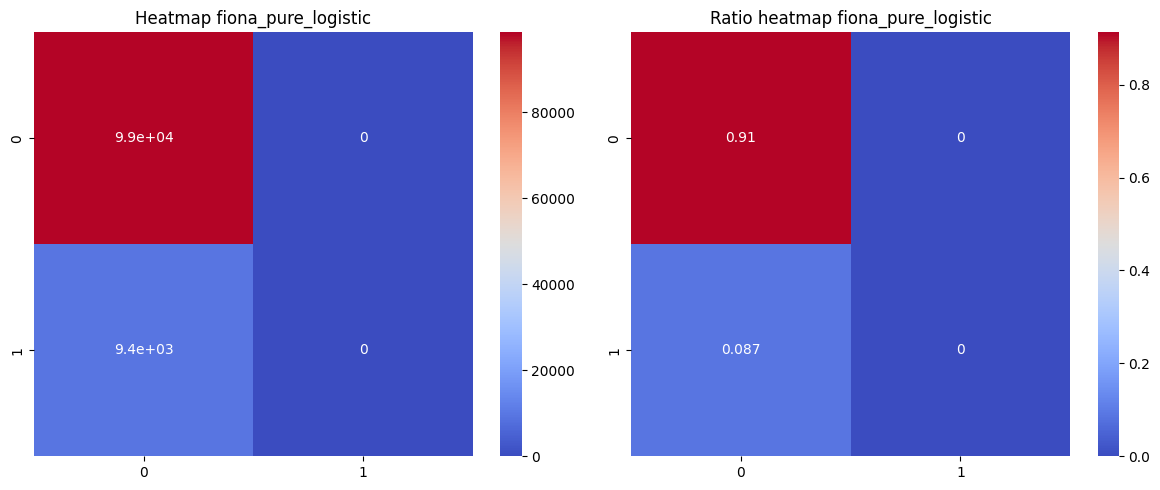

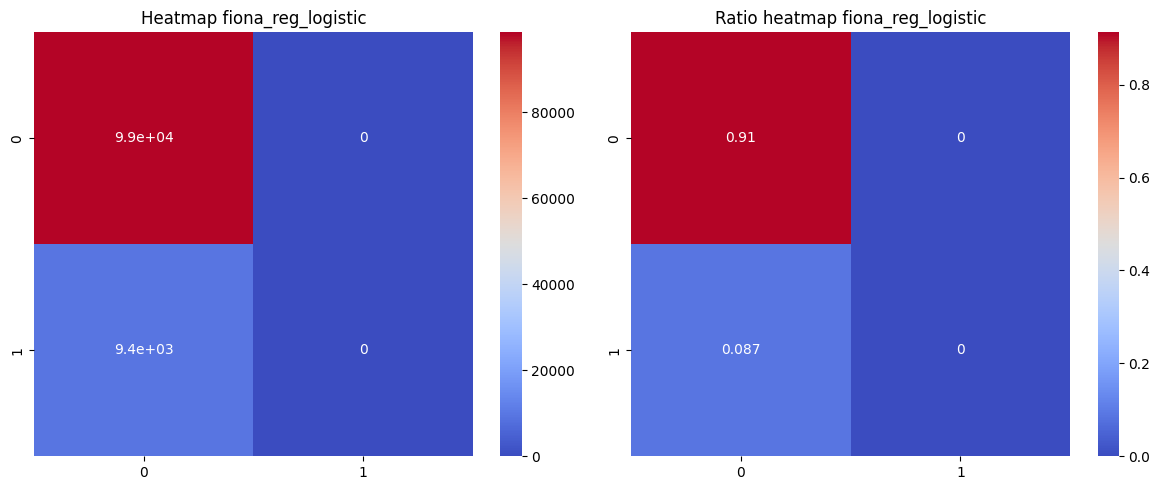

In [94]:
#Pure logistic
#Class choice
logistic_mask_fiona = sigmoid(tx_te @ w_fiona) >= 0.5
y_te_pred_fiona = np.zeros((np.shape(tx_te)[0],1))
y_te_pred_fiona[logistic_mask_fiona] = 1

#Display
plot_heatmap(y_te, y_te_pred_fiona, "fiona_pure_logistic")



#Reg logistic
#Class choice
logistic_mask_fiona_reg = sigmoid(tx_te @ w_fiona_reg) >= 0.5
y_te_pred_fiona_reg = np.zeros((np.shape(tx_te)[0],1))
y_te_pred_fiona_reg[logistic_mask_fiona_reg] = 1

#Display
plot_heatmap(y_te, y_te_pred_fiona_reg, "fiona_reg_logistic")

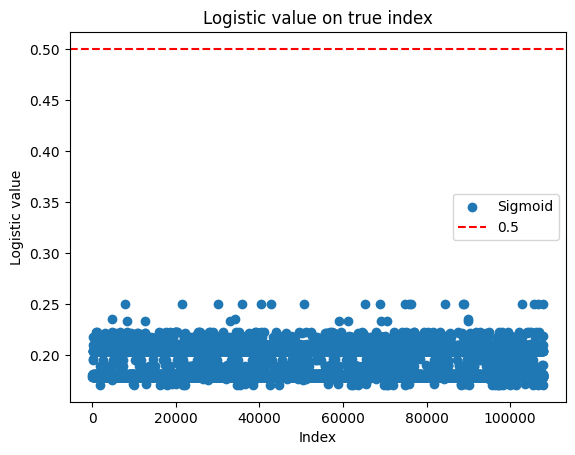

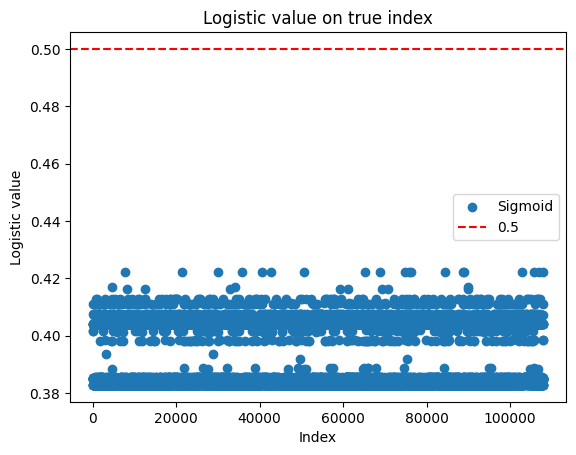

In [60]:
#Pure logistic
#Index of true true
index_true = np.where(y_te == 1)[0]

#Display
plt.scatter(index_true, sigmoid(tx_te @ w_fiona)[index_true], label="Sigmoid")
plt.axhline(y=0.5, color='red', linestyle='--', label='0.5')
plt.xlabel("Index")
plt.ylabel("Logistic value")
plt.title("Logistic value on true index")
plt.legend()
plt.show()


#Reg logistic
#Index of true true
index_true = np.where(y_te == 1)[0]

#Display
plt.scatter(index_true, sigmoid(tx_te @ w_fiona_reg)[index_true], label="Sigmoid")
plt.axhline(y=0.5, color='red', linestyle='--', label='0.5')
plt.xlabel("Index")
plt.ylabel("Logistic value")
plt.title("Logistic value on true index")
plt.legend()
plt.show()

#### d-kNN

In [68]:
#Fit
neigh = sklearn.neighbors.KNeighborsClassifier(n_neighbors=1)
neigh.fit(x_tr, y_tr.ravel())

#Predict
y_te_pred_kNN = neigh.predict(x_te)

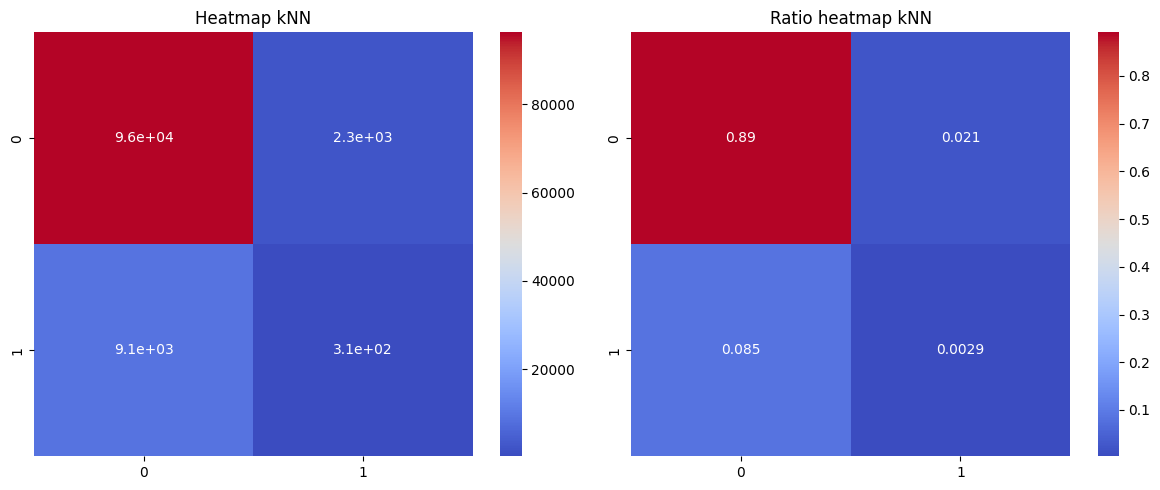

In [95]:
plot_heatmap(y_te, y_te_pred_kNN, "kNN")